Data source: US Bureau of Transportation Statistics (BTS), Airline On-Time Performance. The source contains individual flight records.

Before running: Put the file On_Time_Fights_Aug.csv in the same folder as this notebook.

## 1. Open the dataset

I keep dates, airline, airports, and several numeric fields: arrival delay, departure delay, flight distance and air time. ArrDel15 is a yes or no indicator.

In [196]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
import warnings
from scipy.stats import randint, norm, binom, poisson
from matplotlib.ticker import PercentFormatter


warnings.filterwarnings('ignore')
file = "On_Time_Fights_Aug.csv"

## 1.1 Map

Mapping collumns

In [177]:
columns = [
 'Year','Month','FlightDate','DayOfWeek','Reporting_Airline',
 'Flight_Number_Reporting_Airline','Origin','Dest',
 'DepDelay','ArrDelay','ArrDel15','TaxiOut','AirTime','Distance',
 'Cancelled','Diverted','CancellationCode','CarrierDelay','WeatherDelay',
 'NASDelay','SecurityDelay','LateAircraftDelay',
]

## 1.2 Analysing
Analysing data using head() using important columns

In [ ]:
df = pd.read_csv(file, usecols=[
    "FlightDate", "Month", "Reporting_Airline", "Origin", "Dest",
    "DepDelay", "ArrDelay", "ArrDel15", "Distance", "AirTime", "Cancelled", "DayOfWeek"
])
df.head()



,Month,DayOfWeek,FlightDate,Reporting_Airline,Origin,Dest,DepDelay,ArrDelay,ArrDel15,Cancelled,AirTime,Distance
0,8,7,2026-08-23,DL,PDX,SLC,-1.0,4.0,0.0,0.0,90.0,630.0
1,8,7,2026-08-23,DL,SLC,PDX,-4.0,-12.0,0.0,0.0,87.0,630.0
2,8,1,2026-08-24,DL,PDX,SLC,42.0,34.0,1.0,0.0,85.0,630.0
3,8,1,2026-08-24,DL,SLC,PDX,41.0,47.0,1.0,0.0,103.0,630.0
4,8,2,2026-08-25,DL,PDX,SLC,-8.0,-6.0,0.0,0.0,89.0,630.0


## 2. Descriptive statistics
using 'describe()' that gives me the number of non missing values, mean, standard deviation, minimum, quartiles and maximum. I can look for missing values and the most common airlines.

In [ ]:
print(df[["DepDelay", "ArrDelay", "Distance", "AirTime"]].describe().round(2))
print(df[["DepDelay", "ArrDelay", "Distance", "AirTime"]].median())
print("Missing values:")
print(df.isna().sum())
print("Top origin airports:")
print(df["Origin"].value_counts().head(10))


        DepDelay   ArrDelay   Distance    AirTime
count  597734.00  594207.00  608389.00  594207.00
mean       18.70      13.77     841.81     115.70
std        65.41      67.32     608.61      70.96
min       -42.00     -93.00      31.00       7.00
25%        -6.00     -15.00     399.00      64.00
50%        -1.00      -4.00     680.00      98.00
75%        17.00      17.00    1069.00     145.00
max      4380.00    4381.00    4983.00     633.00
DepDelay     -1.0
ArrDelay     -4.0
Distance    680.0
AirTime      98.0
dtype: float64
Missing values:
Month                    0
DayOfWeek                0
FlightDate               0
Reporting_Airline        0
Origin                   0
Dest                     0
DepDelay             10655
ArrDelay             14182
ArrDel15             14182
Cancelled                0
AirTime              14182
Distance                 0
Failure                  0
dtype: int64
Top origin airports:
Origin
ORD    33187
DEN    28557
DFW    27347
ATL    27221
LAX

In [206]:
print("Mean arrival delay:", df["ArrDelay"].mean().round(2))
print("Median arrival delay:", df["ArrDelay"].median())
print("Standard deviation:", df["ArrDelay"].std().round(2))
print("Minimum:", df["ArrDelay"].min())
print("Maximum:", df["ArrDelay"].max())

variables = ["DepDelay", "ArrDelay", "Distance", "AirTime"]

print("Total flights:", len(df))
print(df[variables].describe().round(2))

print("\nMissing values:")
print(df[variables].isna().sum())

arrival = df["ArrDelay"].dropna()

q1 = arrival.quantile(0.25)
q3 = arrival.quantile(0.75)
print("\nArrival delay statistics:")
print("Mean (minutes):", round(arrival.mean(), 2))
print("Median (minutes):", arrival.median())
print("Sample standard deviation (minutes):", round(arrival.std(ddof=1), 2))
print("Minimum (minutes):", arrival.min())
print("Maximum (minutes):", arrival.max())
print("Range (minutes):", arrival.max() - arrival.min())
print("First quartile (minutes):", q1)
print("Third quartile (minutes):", q3)
print("Interquartile range (minutes):", q3 - q1)

Mean arrival delay: 13.77
Median arrival delay: -4.0
Standard deviation: 67.32
Minimum: -93.0
Maximum: 4381.0
Total flights: 608389
        DepDelay   ArrDelay   Distance    AirTime
count  597734.00  594207.00  608389.00  594207.00
mean       18.70      13.77     841.81     115.70
std        65.41      67.32     608.61      70.96
min       -42.00     -93.00      31.00       7.00
25%        -6.00     -15.00     399.00      64.00
50%        -1.00      -4.00     680.00      98.00
75%        17.00      17.00    1069.00     145.00
max      4380.00    4381.00    4983.00     633.00

Missing values:
DepDelay    10655
ArrDelay    14182
Distance        0
AirTime     14182
dtype: int64

Arrival delay statistics:
Mean (minutes): 13.77
Median (minutes): -4.0
Sample standard deviation (minutes): 67.32
Minimum (minutes): -93.0
Maximum (minutes): 4381.0
Range (minutes): 4474.0
First quartile (minutes): -15.0
Third quartile (minutes): 17.0
Interquartile range (minutes): 32.0


### Figure 1 - Percentage of flights arriving 15+ minutes late by day of the week

Divide number of delayed arrivals by the number of flights with a valid yes or no delay indicator, not by cancelled flights with missing arrival information


In [180]:
#for this purpose, I have to map numeric week day to categorical week day

days = {
    1: "Monday",
    2: "Tuesday",
    3: "Wednesday",
    4: "Thursday",
    5: "Friday",
    6: "Saturday",
    7: "Sunday"
}

df["DayOfWeek"] = df["DayOfWeek"].map(days)

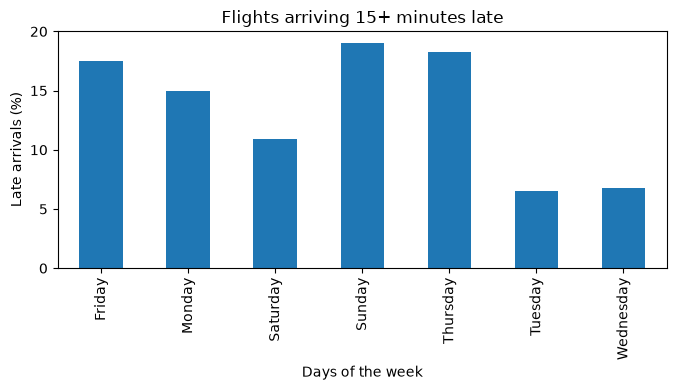

DayOfWeek
Friday       17.5%
Monday       14.9%
Saturday     10.9%
Sunday       19.1%
Thursday     18.2%
Tuesday       6.5%
Wednesday     6.8%
Name: ArrDelay, dtype: str


In [199]:
valid = df[df["ArrDel15"].isin([0, 1])]
late_pct = valid.groupby("DayOfWeek")['ArrDelay'].mean()

late_pct.plot(kind="bar", figsize=(7, 4))
plt.title("Flights arriving 15+ minutes late")
plt.xlabel("Days of the week")
plt.ylabel("Late arrivals (%)")
plt.tight_layout()
plt.show()

print(late_pct.round(1).astype(str) + "%")

### Figure 2 - Distribution of arrival delay by minutes

It shows whether most flights arrive near schedule and whether some have unsually long delays. Only for **visual clarity**, the figure shows delays between -30 and 180 minutes. Descriptive statistics above use all available values.

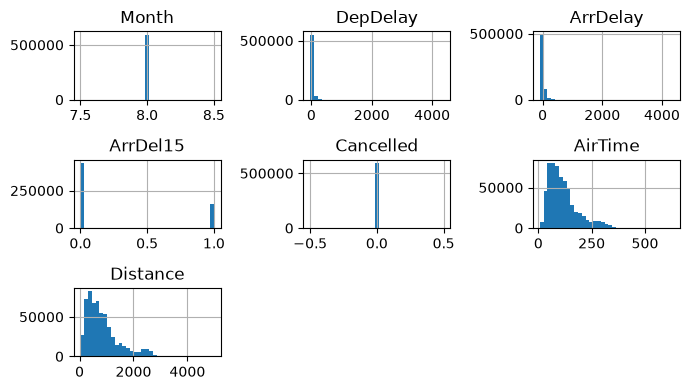

In [182]:
arrival = df['ArrDelay'].dropna()
arrival_plot = df[df["ArrDel15"].between(-30, 180)]
arrival_plot.hist(bins=35, figsize=(7,4))
plt.title("Arrival delay distribuition between -30 to 180 min")
plt.xlabel("Arrival delay per minutes")
plt.ylabel("Number of flights")
plt.tight_layout()
plt.show()

### Figure 3 — Distance versus flight time
A scatter plot that whether longer roates generally involves more delays. For this purpose, I randomly use 3000 samples, the datasett itself is not reduced.

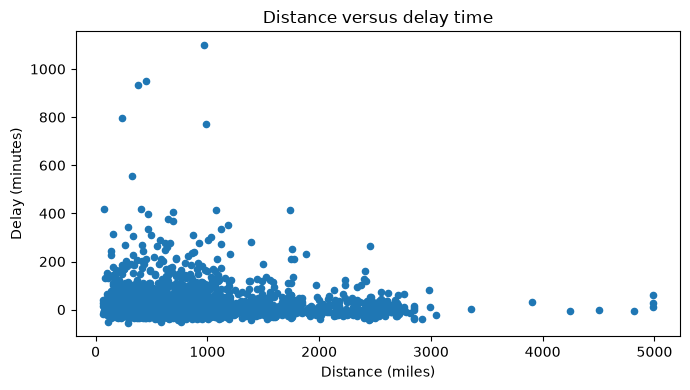

In [183]:
distancePerDelay = df[["Distance", "ArrDelay"]].dropna().sample(3000, random_state =42)
distancePerDelay.plot.scatter(x="Distance", y="ArrDelay",figsize=(7, 4))
plt.title("Distance versus delay time")
plt.xlabel("Distance (miles)")
plt.ylabel("Delay (minutes)")
plt.tight_layout()
plt.show()

## 3. Binomial distribution
If we select 100 flights, how many will be late at least 15 minutes?
X Binomial(n=100,p), E(X)=np, Var(X)=np(1-p)
The graph compares the binomial probabilities with a normal approximation as an illustration of what happens when n is large enough for np and n(1-p) to be reasonably large.

n - Flights quantity.
p - Probability.
E(x) - Expected delayed flights.
Var(x) - Variance of this number.

In [ ]:
# 3. Late-arrival rate and Binomial distribution

arrival_flags = df.loc[df["ArrDel15"].isin([0, 1]), "ArrDel15"]

late_arrivals = arrival_flags.sum()
valid_arrivals = arrival_flags.count()

p = late_arrivals / valid_arrivals
n = 100

print("Flights arriving at least 15 minutes late:", int(late_arrivals))
print("Valid arrival indicators:", valid_arrivals)
print("Late-arrival probability:", round(p, 4))
print("Late-arrival rate (%):", round(p * 100, 2))

print("Expected late arrivals among 100 flights:", round(n * p, 2))
print("Binomial variance:", round(n * p * (1 - p), 2))
print("Probability of 25 or more late arrivals:", binom.sf(24, n, p), 4)

Flights arriving at least 15 minutes late: 159636
Valid arrival indicators: 594207
Late-arrival probability: 0.2687
Late-arrival rate (%): 26.87
Expected late arrivals among 100 flights: 26.87
Binomial variance: 19.65
Probability of 25 or more late arrivals: 0.6987132613718172 4


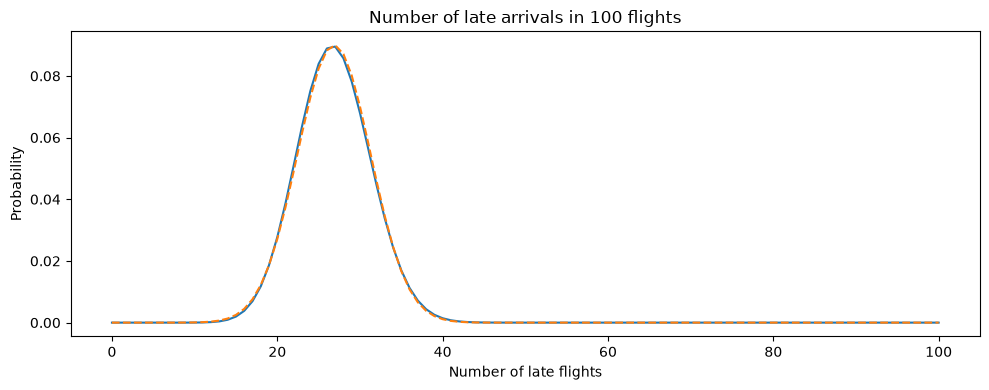

In [184]:
p = valid["ArrDel15"].mean()
n = 100
x = np.arange(0, n + 1) # possible outcomes (0–n+1)

plt.figure(figsize=(10,4))
plt.plot(x, binom.pmf(x, n, p), label="Binomial")
plt.plot(x, norm.pdf(x, n * p, np.sqrt(n * p * (1-p))),
         label="Normal approximation", linestyle="--")
#
plt.title("Number of late arrivals in 100 flights")
plt.xlabel("Number of late flights")
plt.ylabel("Probability")
plt.tight_layout()
plt.show()

## 4. Poisson distribution - Cancellation in a group of 100

**Definition**:  
The **Poisson Distribution** gives us the probability of a given number of
events happening in a fixed interval of time.

Poisson is an approximation, best when q is small. I use it to demonstrate a discrete distribution.

For this purpose with a simple Poisson approximation to observe cancellation rate, you can see how many cancellation might occur among 100 flights.

In [ ]:
# 4. Cancellation rate and Poisson distribution

cancellation_flags = df.loc[df["Cancelled"].isin([0, 1]), "Cancelled"]

cancelled_flights = cancellation_flags.sum()
valid_flights = cancellation_flags.count()

q = cancelled_flights / valid_flights
lam = 100 * q

print("Cancelled flights:", int(cancelled_flights))
print("Valid cancellation indicators:", valid_flights)
print("Cancellation probability:", round(q, 6))
print("Cancellation rate (%):", round(q * 100, 4))
print("Expected cancellations among 100 flights (lambda):", round(lam, 4))

print("Poisson probability of zero cancellations:", poisson.pmf(0, lam), 4)
print("Poisson probability of at least one cancellation:", poisson.sf(0, lam), 4)

Cancelled flights: 11313
Valid cancellation indicators: 608389
Cancellation probability: 0.018595
Cancellation rate (%): 1.8595
Expected cancellations among 100 flights (lambda): 1.8595
Poisson probability of zero cancellations: 0.1557503185904717 4
Poisson probability of at least one cancellation: 0.8442496814095284 4


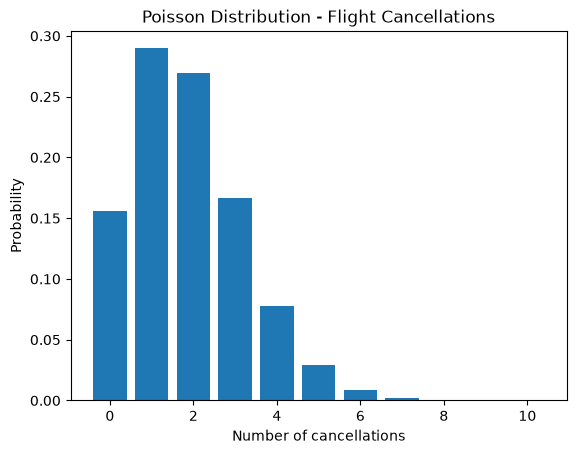

In [185]:

# Probability of cancellation
p = df["Cancelled"].mean()

# Expected cancellations per 100 flights
lambda_value = 100 * p

# Possible number of cancellations
x = np.arange(0, 11)

# Poisson distribution
plt.bar(x, poisson.pmf(x, lambda_value))
plt.xlabel("Number of cancellations")
plt.ylabel("Probability")
plt.title("Poisson Distribution - Flight Cancellations")
plt.show()

## 5. Normal distribution — JFK to LAX air time

Are air times for the **same directional route, JFK → LAX**, reasonably close to a Normal distribution?

Air time is a numerical measurement; mixing all routes creates artificial variation from distance. We calculate the **sample mean** and **sample standard deviation**, then overlay a theoretical Normal curve on the real histogram.

In [ ]:
# 5. JFK to LAX air-time statistics

route = df[
    (df["Origin"] == "JFK") &
    (df["Dest"] == "LAX")
]

air_time = route["AirTime"].dropna()

mean = air_time.mean()
sd = air_time.std(ddof=1)

within_1_sd = air_time.between(mean - sd, mean + sd)
within_2_sd = air_time.between(mean - 2 * sd, mean + 2 * sd)

print("Total JFK to LAX flights:", len(route))
print("Flights with valid air time:", len(air_time))
print("Missing air-time values:", route["AirTime"].isna().sum())

print("Mean air time (minutes):", round(mean, 2))
print("Median air time (minutes):", air_time.median())
print("Sample standard deviation (minutes):", round(sd, 2))

print("Flights within one standard deviation:", int(within_1_sd.sum()))
print("Within one standard deviation (%):", round(within_1_sd.mean() * 100, 2))

print("Flights within two standard deviations:", int(within_2_sd.sum()))
print("Within two standard deviations (%):", round(within_2_sd.mean() * 100, 2))

Total JFK to LAX flights: 916
Flights with valid air time: 876
Missing air-time values: 40
Mean air time (minutes): 314.91
Median air time (minutes): 314.0
Sample standard deviation (minutes): 10.7
Flights within one standard deviation: 617
Within one standard deviation (%): 70.43
Flights within two standard deviations: 829
Within two standard deviations (%): 94.63


Mean: 115.70405767687018
Standard deviation: 70.95826327891176


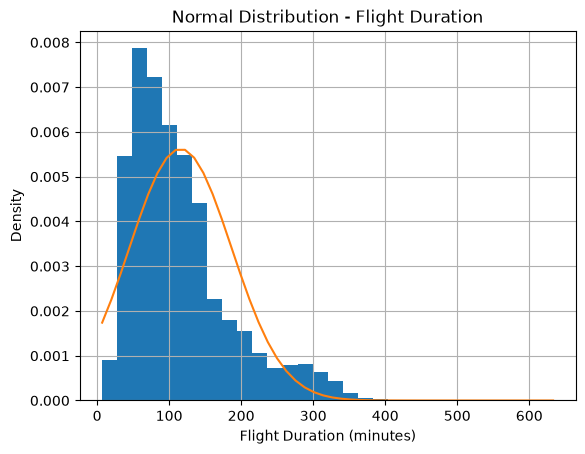

In [186]:
# print("Airport origin:", df['Origin'])
# print("Airport dest:", df['Dest'])
# Select one route
flights = df.query("Origin == 'JFK' and Dest == 'LAX'")
# Flight duration
time = df["AirTime"].dropna()

# Mean and standard deviation
mu = time.mean()
sd = time.std()

print("Mean:", mu)
print("Standard deviation:", sd)

# Plot histogram
time.hist(bins=30, density=True)

# Normal distribution
x = np.linspace(time.min(), time.max())
plt.plot(x, norm.pdf(x, mu, sd))

plt.title("Normal Distribution - Flight Duration")
plt.xlabel("Flight Duration (minutes)")
plt.ylabel("Density")
plt.show()

## 6. Extra
- Top 10 airports with most cancellations
- Top 10 airports with most delays
- Top 10 airports with lowest failure rates

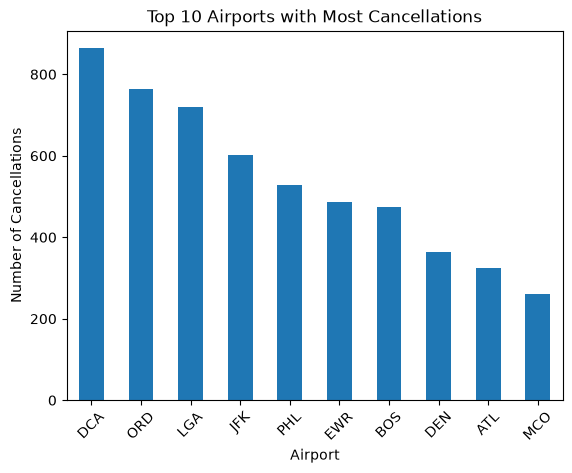

In [187]:
#Top 10 airports with most cancellations
top_cancellations = df[df["Cancelled"] == 1]["Origin"].value_counts().head(10)

top_cancellations.plot(kind="bar")

plt.title("Top 10 Airports with Most Cancellations")
plt.xlabel("Airport")
plt.ylabel("Number of Cancellations")
plt.xticks(rotation=45)
plt.show()

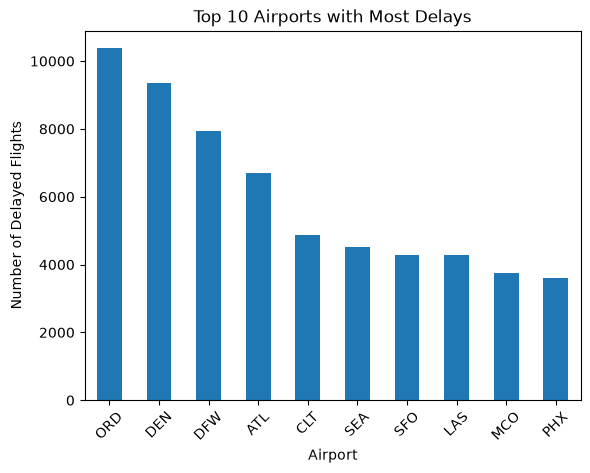

In [188]:
#Top 10 airports with most delays
top_delays = df[df["DepDelay"] >= 15]["Origin"].value_counts().head(10)

top_delays.plot(kind="bar")

plt.title("Top 10 Airports with Most Delays")
plt.xlabel("Airport")
plt.ylabel("Number of Delayed Flights")
plt.xticks(rotation=45)
plt.show()

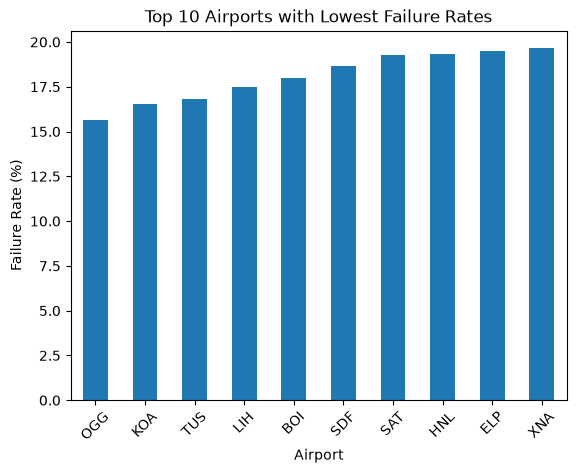

In [189]:
#Top 10 airports with lowest failure rates

# Create failure column
df["Failure"] = (df["Cancelled"] == 1) | (df["DepDelay"] >= 15)

# Calculate failure rate
failure_rate = df.groupby("Origin")["Failure"].mean() * 100

# Number of flights per airport
flights = df["Origin"].value_counts()

# Only airports with at least 1000 flights
failure_rate = failure_rate[flights >= 1000]

# Top 10 lowest failure rates
failure_rate.nsmallest(10).plot(kind="bar")

plt.title("Top 10 Airports with Lowest Failure Rates")
plt.xlabel("Airport")
plt.ylabel("Failure Rate (%)")
plt.xticks(rotation=45)
plt.show()